In [ ]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler

from google.colab import files
uploaded = files.upload()

df = pd.read_csv('train.csv')

print(df.head())

Saving train.csv to train (1).csv
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition 

In [ ]:
print(df.shape)







(1460, 81)


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
print(df.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


In [ ]:
continuous = ['LotArea', 'LotFrontage', 'GrLivArea', 'GarageArea']

discrete = ['BedroomAbvGr', 'TotRmsAbvGrd', 'Fireplaces']

ordinal = ['OverallQual', 'OverallCond']

nominal = ['Neighborhood', 'HouseStyle', 'RoofStyle']

print("Continuous:", continuous)
print("Discrete:", discrete)
print("Ordinal:", ordinal)
print("Nominal:", nominal)

Continuous: ['LotArea', 'LotFrontage', 'GrLivArea', 'GarageArea']
Discrete: ['BedroomAbvGr', 'TotRmsAbvGrd', 'Fireplaces']
Ordinal: ['OverallQual', 'OverallCond']
Nominal: ['Neighborhood', 'HouseStyle', 'RoofStyle']


In [ ]:
for col in df.select_dtypes(include=np.number):
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include='object'):
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum().sum())

0


In [ ]:
df = df.drop_duplicates()

print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [ ]:
#outliers
cols = df.select_dtypes(include=np.number).columns.drop('Id')

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

print("Outliers handled")

Outliers handled


In [ ]:
#min-max
cols = df.select_dtypes(include=np.number).columns.drop('Id')

minmax = MinMaxScaler()

df_minmax = df.copy()

df_minmax[cols] = minmax.fit_transform(df[cols])

print(df_minmax.head())

   Id  MSSubClass MSZoning  LotFrontage   LotArea Street Alley LotShape  \
0   1        0.32       RL     0.440789  0.430367   Pave  Grvl      Reg   
1   2        0.00       RL     0.638158  0.501390   Pave  Grvl      Reg   
2   3        0.32       RL     0.480263  0.603292   Pave  Grvl      IR1   
3   4        0.40       RL     0.375000  0.498302   Pave  Grvl      IR1   
4   5        0.32       RL     0.690789  0.789186   Pave  Grvl      IR1   

  LandContour Utilities  ... PoolArea PoolQC  Fence MiscFeature MiscVal  \
0         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
1         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
2         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
3         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
4         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   

     MoSold YrSold  SaleType  SaleCondition  SalePrice  
0  0.090909   0.50        WD         Norm

In [ ]:
#z score
scaler = StandardScaler()

df_zscore = df.copy()

df_zscore[cols] = scaler.fit_transform(df[cols])

print(df_zscore.head())

   Id  MSSubClass MSZoning  LotFrontage   LotArea Street Alley LotShape  \
0   1    0.131067       RL    -0.237456 -0.333244   Pave  Grvl      Reg   
1   2   -0.935733       RL     0.633321 -0.013189   Pave  Grvl      Reg   
2   3    0.131067       RL    -0.063300  0.446022   Pave  Grvl      IR1   
3   4    0.397766       RL    -0.527714 -0.027104   Pave  Grvl      IR1   
4   5    0.131067       RL     0.865528  1.283733   Pave  Grvl      IR1   

  LandContour Utilities  ... PoolArea PoolQC  Fence MiscFeature MiscVal  \
0         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
1         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
2         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
3         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   
4         Lvl    AllPub  ...      0.0     Gd  MnPrv        Shed     0.0   

     MoSold    YrSold  SaleType  SaleCondition  SalePrice  
0 -1.599111  0.138777        WD       

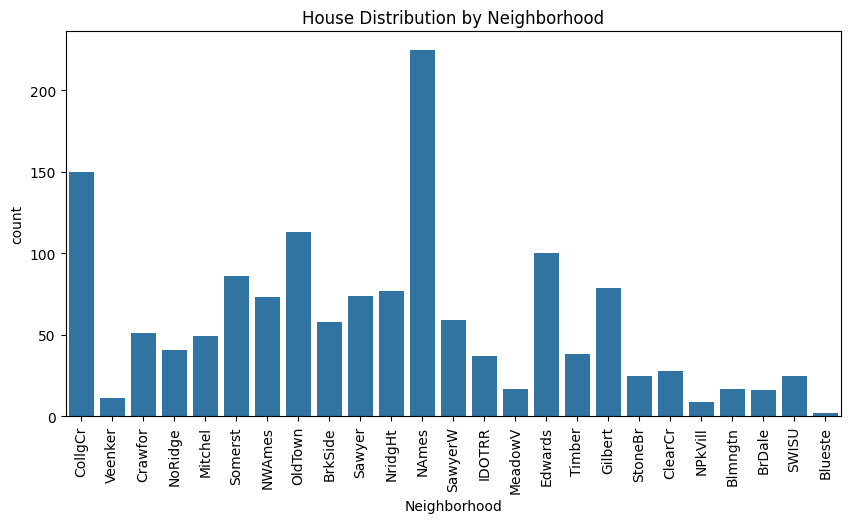

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='Neighborhood')

plt.title("House Distribution by Neighborhood")
plt.xticks(rotation=90)

plt.show()

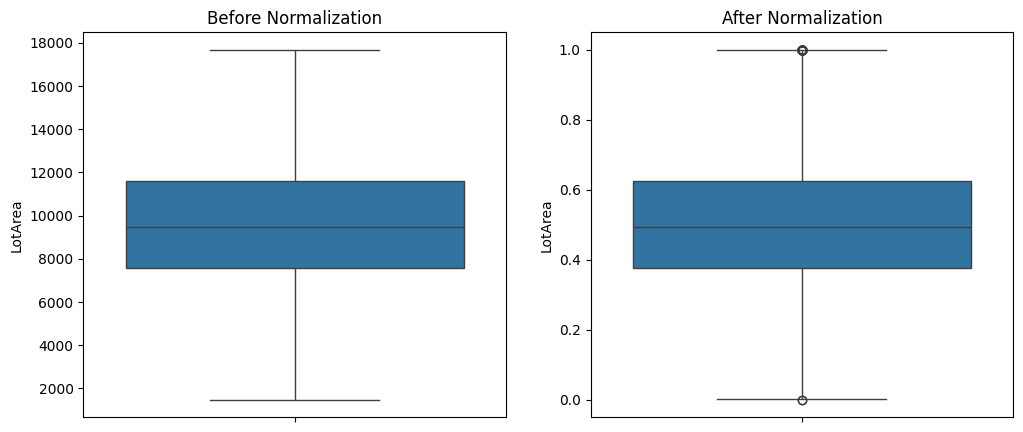

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.boxplot(y=df['LotArea'], ax=axes[0])
axes[0].set_title("Before Normalization")

sns.boxplot(y=df_minmax['LotArea'], ax=axes[1])
axes[1].set_title("After Normalization")

plt.show()

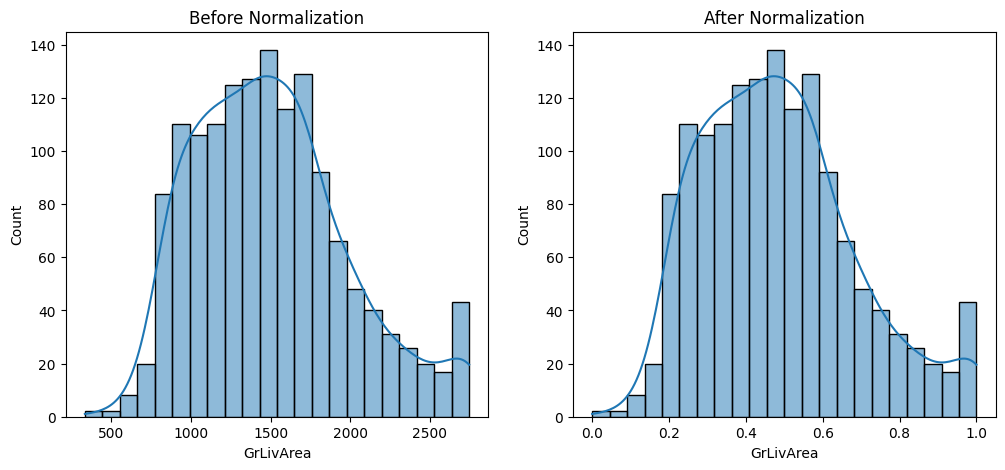

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

sns.histplot(df['GrLivArea'], kde=True, ax=axes[0])
axes[0].set_title("Before Normalization")

sns.histplot(df_minmax['GrLivArea'], kde=True, ax=axes[1])
axes[1].set_title("After Normalization")

plt.show()

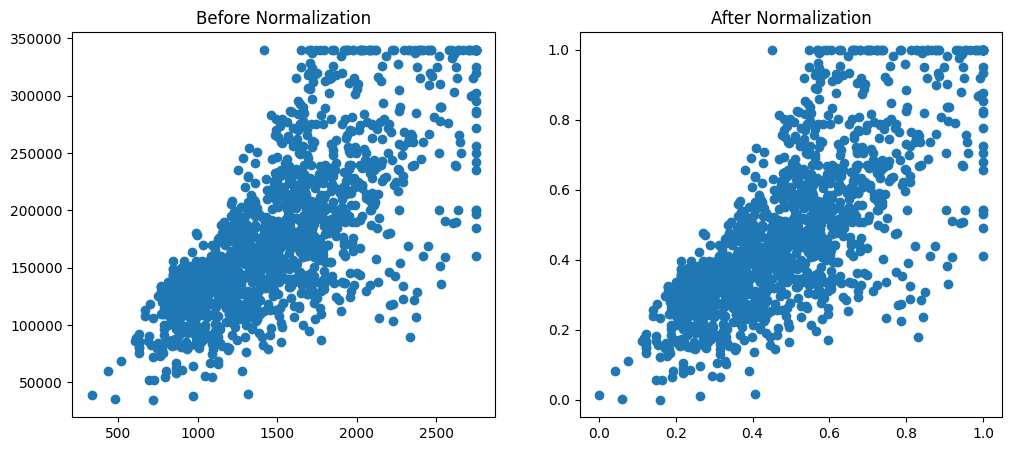

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

axes[0].scatter(df['GrLivArea'], df['SalePrice'])
axes[0].set_title("Before Normalization")

axes[1].scatter(df_minmax['GrLivArea'], df_minmax['SalePrice'])
axes[1].set_title("After Normalization")

plt.show()